# Final deliverable: delivery route optimization (CVRP and CVRPTW)

**CesiCDP for the ADEME Smart Multimodal Mobility call.** Team: Pablo, Dag, Farida.

Graded deliverable, due the day before the presentation. Each section below names its owner (see
`docs/content/task-separation.md`). Keep the story first: every table or figure is followed by one
sentence saying what it means.

## 1. Data formalization  (Person 1)

The road network is reduced to a **complete directed graph** on the depot and the customers; the
time of a trip $i \to j$ is the fastest path in the network, computed once. The depot appears
twice, node $0$ (departure) and node $n + 1$ (return), so each truck has a departure and a return
time. All times are minutes after midnight.

| Symbol | Meaning | Unit |
| --- | --- | --- |
| $V^+ = \{1, \dots, n\}$ | customers | |
| $V = \{0\} \cup V^+ \cup \{n+1\}$ | nodes; $0$ and $n+1$ are the depot | |
| $A$ | trips: depot to customer, customer to customer, customer to depot, and $0 \to n+1$ (truck not used) | |
| $\mathcal{K} = \{1, \dots, K\}$ | identical trucks | |
| $\mathcal{H} = \{0, \dots, 23\}$ | hours of the day | |
| $Q$ | capacity of a truck | units |
| $q_i$ | demand of customer $i$ ($q_i \le Q$) | units |
| $[e_i, l_i]$ | time window: service must **start** in it | min |
| $s_i$ | service time at customer $i$ ($s_0 = 0$) | min |
| $[e_0, l_0]$ | working day of the depot | min |
| $c_{ij}$ | travel time from $i$ to $j$ on empty roads | min |
| $\rho_h$ | traffic intensity of hour $h$ ($\rho_h \ge 1$) | |
| $c_{ij}^h = \rho_h \, c_{ij}$ | **traffic matrix**: travel time when leaving $i$ during hour $h$ | min |

The $\rho_h$ values (peaks 1.75 to 1.80 from 7:00 to 9:00 and from 17:00 to 19:00, 1.00 at night)
are assumptions of notebook 01, to be replaced by measured data. The model only reads numbers from
the matrix, so measured values change no equation.

**Decision variables**

| Variable | Domain | Meaning |
| --- | --- | --- |
| $x_{ij}^k$ | $\{0, 1\}$ | truck $k$ drives directly from $i$ to $j$ |
| $y_{ih}$, $y_{0h}^k$ | $\{0, 1\}$ | the truck leaves customer $i$ (the depot, for truck $k$) during hour $h$ |
| $t_0^k$, $t_{n+1}^k$ | $\ge 0$, min | truck $k$ leaves the depot, is back |
| $a_i$, $w_i$, $t_i$ | $\ge 0$, min | arrival, waiting and service start at customer $i$ |

The travel time is fixed by the hour of departure, so a later departure may arrive earlier (the
first in, first out property is not guaranteed): an accepted simplification.

**Benchmark data.** The Solomon instances (56 files, 100 customers, PyVRP/VRPLIB copy) give
$c_{ij}$ as Euclidean distances truncated to one decimal, the convention of their best known
values, and no traffic ($\rho_h = 1$).

## 2. Complexity  (Person 1)

**Decision version (DEC).** Given an instance and a number $B$, is there a feasible plan of total
route duration at most $B$?

**DEC is in NP.** A certificate is the list of routes with each truck's departure time (a rational
of polynomial size: an optimal departure can be taken at a breakpoint of the piecewise linear
schedule). Checking
that every customer appears once, that each load is at most $Q$, and computing the schedule along
each route (one matrix read, one comparison per visit) takes $O(n + K)$ operations; comparing the
total with $B$ is one more.

**Hamiltonian cycle reduces to DEC.** Let $G = (U, E)$ be a graph with $U = \{u_0, \dots, u_m\}$,
$m \ge 2$. Build in $O(m^2)$ the instance: depot $u_0$, customers $u_1, \dots, u_m$, $K = 1$,
$q_i = 1$, $Q = m$, $s_i = 0$, every window equal to the whole day, $\rho_h = 1$ for every $h$,
$c_{ij} = 1/(m+1)$ minute if $\{u_i, u_j\} \in E$ and $c_{ij} = 2/(m+1)$ otherwise, and $B = 1$
(so every plan fits in the day whatever $m$).

- If $G$ has a Hamiltonian cycle, start it at $u_0$: the truck follows it, each of its $m + 1$
  trips takes $1/(m+1)$, no window makes it wait, so the duration is $1 \le B$.
- If a plan has duration at most $1$: the single truck visits the $m$ customers once each and
  returns, so its route is a cycle through all $m + 1$ nodes made of $m + 1$ trips. Each trip takes
  at least $1/(m+1)$, so all of them take exactly $1/(m+1)$, and each one is an edge of $G$: the
  route is a Hamiltonian cycle of $G$.

Hamiltonian cycle is NP-complete (Karp, 1972), so DEC is **NP-complete** and the optimization
problem is **NP-hard**. The instance built uses only the special case $K = 1$, $\rho_h = 1$, wide
windows, which is the travelling salesman problem: capacity, windows and traffic add constraints
to a problem that is already hard. Capacity alone is hard too: deciding whether $K$ trucks can
carry the demands is bin packing (Garey and Johnson, 1979).

**Consequence.** No polynomial exact algorithm is expected. Section 4 measures where the exact ILP
stops being usable; sections 5 to 8 use metaheuristics for the realistic sizes.

## 3. Complete ILP  (Person 1)

$$
\begin{aligned}
\min \quad & z = \sum_{k \in \mathcal{K}} \big( t_{n+1}^k - t_0^k \big) \\[4pt]
\text{s.t.} \quad
& \sum_{k} \sum_{j : (i, j) \in A} x_{ij}^k = 1 && \forall i \in V^+ && \text{(1) each customer served once}\\
& \sum_{j} x_{0j}^k = 1, \quad \sum_{i} x_{i, n+1}^k = 1 && \forall k && \text{(2), (4) each truck leaves and returns}\\
& \sum_{i} x_{ij}^k = \sum_{i} x_{ji}^k && \forall j \in V^+,\ k && \text{(3) a truck that enters leaves}\\
& \sum_{i \in V^+} q_i \sum_{j} x_{ij}^k \le Q && \forall k && \text{(5) capacity}\\
& \sum_h y_{ih} = 1, \quad \sum_h 60h\, y_{ih} \le t_i + s_i \le \sum_h 60(h+1)\, y_{ih} && \forall i \in V^+ && \text{(6), (7) departure hour}\\
& \sum_h y_{0h}^k = 1, \quad \sum_h 60h\, y_{0h}^k \le t_0^k \le \sum_h 60(h+1)\, y_{0h}^k && \forall k && \text{(6), (7) at the depot}\\
& \Big\lvert\, a_j^k - t_i^k - s_i - \sum_h c_{ij}^h\, y_{ih}^k \,\Big\rvert \le M (1 - x_{ij}^k) && \forall (i, j) \in A,\ k && \text{(8) arrival with traffic}\\
& t_i = a_i + w_i, \quad e_i \le t_i \le l_i && \forall i \in V^+ && \text{(9), (10) wait, then serve}\\
& t_0^k \ge e_0, \quad t_{n+1}^k \le l_0 && \forall k && \text{(10) working day}\\
& x,\ y \in \{0, 1\}, \quad a,\ w,\ t \ge 0 && && \text{(11)}
\end{aligned}
$$

Shorthands in (8): $t_i^k$ is $t_i$ at a customer and $t_0^k$ at the depot, $a_j^k$ is $a_j$ at a
customer and $t_{n+1}^k$ at the return, $y_{ih}^k$ is $y_{ih}$ at a customer and $y_{0h}^k$ at the
depot. $M = 2880$ (two days) exceeds every possible value of
$\lvert a_j - t_i - s_i - c_{ij}^h \rvert$ within a working day, so (8) is inactive when
$x_{ij}^k = 0$. The absolute value stands for two linear inequalities; since $c_{ij}^h + s_i > 0$,
times increase along a route and (8) also forbids subtours. $w_i$ is kept so that the waiting
appears in the solution; it could be replaced by $t_i \ge a_i$. Every line is linear: the model is a mixed
integer linear program with $K \lvert A \rvert$ variables $x$, $24 (n + K)$ variables $y$ and
$3n + 2K$ real variables.

**What the code solves** (`src/cvrp/ilp.py`)

| Function | Model | Used for |
| --- | --- | --- |
| `solve_tdvrptw` | the model above, constraints (1) to (11) | exact optimum with traffic, small $n$ |
| `solve_cvrptw` | benchmark variant: $\rho_h = 1$, two-index $x_{ij}$, objective replaced by total distance $\sum c_{ij} x_{ij}$ | the Solomon benchmark |
| `solve_cvrp_flow`, `_rcc`, `_mtz` | the same variant without windows | CVRP, lower bounds |

The Solomon best known values minimize **total distance** with travel time equal to distance and
no traffic. With $\rho_h = 1$ our objective equals that distance plus the service times (a
constant) plus the waiting, so the benchmark variant optimizes our objective without its waiting
term: it measures the routing part of the model, the only one for which published optima exist. The metaheuristics take the route cost as a function, so the
same search runs on the duration with traffic (`cvrp.tabu.duration_cost`, GRASP
`objective="duration"`).

The cell below solves the model on the toy instance of notebook 01 and compares it with an
enumeration of every partition, visiting order and departure time (0.25 min steps).

In [1]:
import itertools
import sys
from functools import lru_cache
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

from cvrp import Instance
from cvrp.ilp import solve_tdvrptw
from cvrp.tabu import RHO

coords = np.array([[0, 0], [1, 0], [2, 0], [0, 1], [0, 2], [-1, 0], [0, -1]], dtype=float)
q = np.array([0, 4, 4, 3, 3, 5, 5])
e = np.array([360, 480, 480, 420, 540, 600, 600], dtype=float)
l = np.array([1200, 540, 660, 480, 600, 840, 840], dtype=float)
s = np.array([0, 10, 10, 10, 10, 10, 10], dtype=float)
c = 10 * np.linalg.norm(coords[:, None] - coords[None], axis=2)
toy = Instance("toy", coords, q, capacity=10, num_vehicles=3, ready_times=e, due_times=l,
               service_times=s, dist=c)
res = solve_tdvrptw(toy, RHO, time_limit=60)


def duration(route, t0):
    # Route duration leaving the depot at t0, or None if a window is missed.
    i, t = 0, t0
    for j in route + [0]:
        leave = t + s[i]
        arrive = leave + RHO[int(leave // 60)] * c[i, j]
        if j == 0:
            return arrive - t0 if arrive <= l[0] else None
        t = max(arrive, e[j])
        if t > l[j]:
            return None
        i = j


@lru_cache(None)
def best_route(customers):
    if q[list(customers)].sum() > toy.capacity:
        return np.inf
    return min((d for p in itertools.permutations(customers) for t0 in np.arange(e[0], l[0], 0.25)
                if (d := duration(list(p), t0)) is not None), default=np.inf)


def partitions(items, k):
    if not items:
        yield []
        return
    for p in partitions(items[1:], k):
        for i in range(len(p)):
            yield p[:i] + [p[i] + [items[0]]] + p[i + 1:]
        if len(p) < k:
            yield p + [[items[0]]]


enum = min(sum(best_route(tuple(sorted(r))) for r in p) for p in partitions(list(range(1, 7)), 3))
print(f"ILP (constraints 1 to 11): {res.status}, z = {res.objective:.2f} min, routes "
      f"{res.solution.routes}, {res.n_vars} variables, {res.seconds:.1f} s")
print(f"enumeration: z = {enum:.2f} min; hand solution of notebook 01: 256.50 min")

ILP (constraints 1 to 11): Optimal, z = 247.16 min, routes [[4, 2], [3, 1], [6, 5]], 369 variables, 1.1 s
enumeration: z = 247.16 min; hand solution of notebook 01: 256.50 min


The ILP and the enumeration agree on the optimum: the code optimizes the model as written. It is
9 minutes shorter than the hand solution of notebook 01, which paired the customers differently.

## 4. Exact approach in practice  (Person 1)

**Question.** Up to which size does the ILP prove the optimum, and how good are its bounds?
`experiments/exact_study.py` solves growing sub-instances (the depot and the first $n$ customers)
with HiGHS on one thread and a 60 s limit per solve, and writes `results/exact_*.csv`:

| Experiment | Instances | Model |
| --- | --- | --- |
| 4.1 | A-n32-k5, B-n31-k5, $n = 6$ to 16 | CVRP, three formulations (MTZ, flow, capacity cuts) |
| 4.2 | Solomon C101, R101, RC101, $n = 5$ to 100 | benchmark variant (distance, $\rho_h = 1$), with one Tabu Search run of 5 s as upper bound |
| 4.3 | Solomon C101, R101, RC101, $n = 3$ to 10, time 0 at 8:00 | the model of section 3, with $\mathcal{H}$ extended to two days ($\{0, \dots, 47\}$, same $\rho_h$ each day) because the C101 day ends after midnight |

The three CVRP formulations add to the two-index core ($x_{ij}$, degrees, fleet) one way to forbid
subtours and overloads: **MTZ**, a load $u_j \ge u_i + q_j - Q(1 - x_{ij})$ with
$q_i \le u_i \le Q$; **flow**, a load on board $f_{ij}$ with $q_j x_{ij} \le f_{ij} \le (Q - q_i) x_{ij}$
and $\sum_i f_{ij} - \sum_k f_{jk} = q_j$; **capacity cuts**,
$\sum_{i \notin S, j \in S} x_{ij} \ge \lceil q(S) / Q \rceil$ for the sets $S$ found violated, added round
by round.

The **root gap** is $100\,(z^* - z_{LP}) / z^*$, where $z^*$ is the best integer value and $z_{LP}$
the LP relaxation (for capacity cuts, the root LP with its cuts).

,proven_optimal,runs,median_s,mean_root_gap
model,,,,
MTZ,6,12,42.57,50.05
capacity cuts,12,12,0.03,0.57
flow,12,12,1.34,22.55


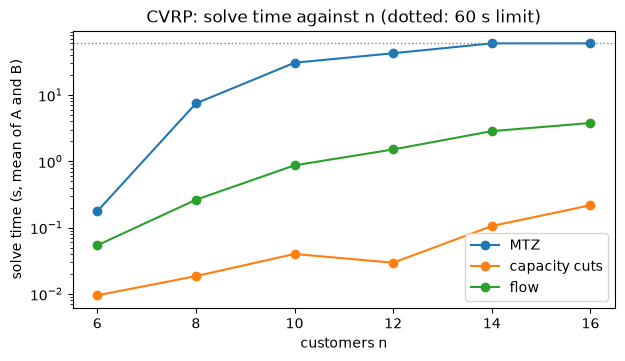

In [2]:
import matplotlib.pyplot as plt

RES = ROOT / "results"
cvrp = pd.read_csv(RES / "exact_cvrp.csv")
tw = pd.read_csv(RES / "exact_cvrptw.csv")
td = pd.read_csv(RES / "exact_traffic.csv")
for df in (cvrp, tw, td):
    df["root_gap"] = (100 * (df.objective - df.lp_bound) / df.objective).clip(lower=0)
    df["optimal"] = df.status.eq("Optimal")

t41 = cvrp.groupby("model").agg(
    proven_optimal=("optimal", "sum"),
    runs=("optimal", "size"),
    median_s=("seconds", "median"),
    mean_root_gap=("root_gap", "mean"),
)
display(t41.round(2))

fig, ax = plt.subplots(figsize=(7, 3.6))
for model, g in cvrp.groupby("model"):
    m = g.groupby("n").seconds.mean()
    ax.plot(m.index, m.values, marker="o", label=model)
ax.axhline(60, color="grey", ls=":", lw=1)
ax.set(yscale="log", xlabel="customers n", ylabel="solve time (s, mean of A and B)",
       title="CVRP: solve time against n (dotted: 60 s limit)")
ax.legend()
plt.show()

**Reading 4.1.** The capacity cut formulation proves every optimum (12 of 12) in at most 0.35 s,
because its LP relaxation is almost tight (mean root gap 0.6 %); the flow formulation also proves
all of them, in at most 4.4 s; MTZ, whose relaxation is far from the optimum (root gap 50 %), stops
at the 60 s limit from $n = 10$ on clustered B and $n = 14$ on random A. The strength of the LP
relaxation, not the number of variables, decides how far each CVRP formulation goes here.

In [3]:
t42 = tw.assign(
    bound_gap=(100 * (tw.objective - tw.bound) / tw.objective).clip(lower=0),
    tabu_gap=100 * (tw.tabu - tw.objective) / tw.objective,
)[["instance", "n", "status", "seconds", "objective", "bound", "bound_gap", "root_gap", "tabu",
   "tabu_gap"]]
display(t42.round(2))

,instance,n,status,seconds,objective,bound,bound_gap,root_gap,tabu,tabu_gap
0,C101[:5],5,Optimal,0.06,42.3,42.3,0.00,44.90,42.3,0.00
1,C101[:10],10,Optimal,0.02,58.1,58.1,0.00,18.15,58.1,-0.00
2,C101[:15],15,Optimal,0.03,141.6,141.6,0.00,29.57,141.6,-0.00
3,C101[:20],20,Optimal,0.05,175.0,175.0,0.00,16.00,175.0,-0.00
4,C101[:25],25,Optimal,0.08,191.3,191.3,0.00,13.86,191.3,0.00
5,C101[:50],50,Optimal,0.29,362.4,362.4,0.00,10.88,362.4,0.00
6,C101[:75],75,Optimal,1.05,649.2,649.2,0.00,17.83,649.2,0.00
7,C101[:100],100,Optimal,3.06,827.3,827.3,0.00,9.64,827.3,0.00
8,R101[:5],5,Optimal,0.02,156.2,156.2,0.00,16.53,156.2,0.00
9,R101[:10],10,Optimal,0.05,269.2,269.2,0.00,26.31,269.2,0.00


**Reading 4.2.** With time windows the ILP proves the optimum of the full C101 and R101 (100
customers) in about 3 s, and its values equal the best known ones (827.3 and 1637.7), which checks
both the model and the distance convention. On RC101 it stops at the 60 s limit from $n = 50$ on,
with a gap between solution and bound of 6 to 13 %. The root gap does not explain this (R101 has
50 % and is proven in 3 s): mixed clustered and random customers make the branching harder. One
Tabu Search run of 5 s matches the optimum on 18 of the 21 proven
cases (at most 1.1 % above it) and beats the ILP's best solution on RC101 with 50 customers: the
exact method is the reference on small or tight cases, a metaheuristic is needed beyond them.

,instance,n,status,seconds,objective,bound,bound_gap,lp_bound,variables
0,C101[:3],3,Optimal,0.39,350.64,350.64,0.00,-3708.0,342
1,C101[:4],4,Optimal,1.26,443.55,443.55,0.00,-4944.0,488
2,C101[:5],5,Optimal,2.62,542.06,542.06,0.00,-6180.0,660
3,C101[:6],6,Optimal,4.75,647.82,647.76,0.01,-7416.0,864
4,C101[:7],7,Optimal,30.70,740.19,740.15,0.01,-8652.0,1106
5,C101[:8],8,Optimal,52.85,835.41,835.35,0.01,-9888.0,1392
6,C101[:9],9,TimeLimit,60.20,960.11,-1263.35,NaN,-11124.0,1728
7,C101[:10],10,TimeLimit,60.26,1080.78,-1480.07,NaN,-12360.0,2120
8,R101[:3],3,Optimal,0.15,161.64,161.64,0.00,-690.0,342
9,R101[:4],4,Optimal,0.53,217.04,217.04,0.00,-920.0,488


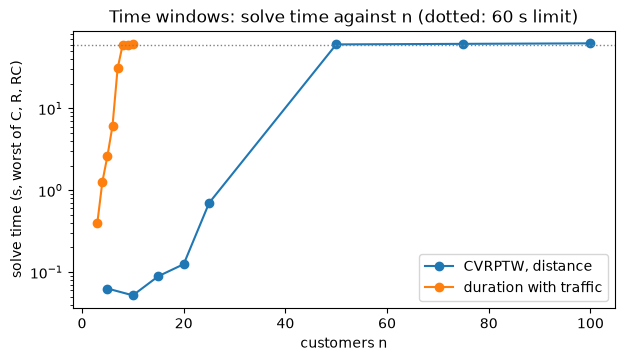

In [4]:
gap = (100 * (td.objective - td.bound) / td.objective).clip(lower=0)
td["bound_gap"] = gap.where(td.bound > 0)  # n/a when the bound is not positive
display(td[["instance", "n", "status", "seconds", "objective", "bound", "bound_gap", "lp_bound",
            "variables"]].round(2))

fig, ax = plt.subplots(figsize=(7, 3.6))
for label, df in [("CVRPTW, distance", tw), ("duration with traffic", td)]:
    m = df.groupby("n").seconds.max()
    ax.plot(m.index, m.values, marker="o", label=label)
ax.axhline(60, color="grey", ls=":", lw=1)
ax.set(yscale="log", xlabel="customers n", ylabel="solve time (s, worst of C, R, RC)",
       title="Time windows: solve time against n (dotted: 60 s limit)")
ax.legend()
plt.show()

**Reading 4.3.** The model with traffic proves the optimum up to 7 customers on every instance
(8 on C101 and R101), then stops at the 60 s limit with a bound far below the solution. Its LP
relaxation is useless as a bound: with $x$ fractional, the big-M of (8) is switched off, every
truck "returns" at $e_0$ and leaves at $l_0$, and the LP value is $-n\,(l_0 - e_0)$. One departure
hour per stop multiplies the variables by 24 (48 here) and the big-M keeps the relaxation weak, so the exact model with traffic serves to check the
definition of the objective on small cases (section 3), not to plan a day.

**Where the exact approach stops.** Without windows: MTZ at 10 to 14 customers; flow and capacity
cuts solve every tested size (up to 16, at most 4.4 s), so their limit lies beyond. With windows, without traffic: 100 customers when the windows
are tight on clustered or random customers (C101, R101), fewer than 50 on mixed RC101. With
traffic: 7 to 8 customers. Beyond that, the metaheuristics of sections 5 to 8 give the solutions,
and the ILP values of 4.2 remain the reference used to measure their gap.

## 5. Chosen metaheuristic: ALNS with simulated annealing acceptance  (Person 2)
> TODO: solution encoding, neighborhood structure, destroy and repair operators, adaptive
> weights, acceptance and cooling. Follow `docs/content/technical/metaheuristic.md`.

## 6. Implementation  (Person 2)



In [ ]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))  # works without `pip install -e .`

import numpy as np
import matplotlib.pyplot as plt

from cvrp import Instance, Solution

In [ ]:
from cvrp.alns import ALNSParams, alns
from cvrp.construct import nearest_neighbor
from cvrp.neighborhoods import local_search
from cvrp.viz import plot_convergence, plot_routes

inst = Instance.random(60, capacity=100, seed=1, distribution="clustered")
start = nearest_neighbor(inst)
res = alns(inst, ALNSParams(iterations=1000), seed=1, initial=start)
best = local_search(res.best, inst)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_routes(inst, start, ax=axes[0], title=f"nearest neighbor: {start.cost(inst):.1f}")
plot_routes(inst, best, ax=axes[1], title=f"ALNS + local search: {best.cost(inst):.1f}")
plt.show()
plot_convergence(res.best_history, res.current_history); plt.show()
print("feasible:", best.is_feasible(inst), "| operator weights:", res.destroy_weights)

## 7. Test cases  (Person 2)
> TODO: point to `tests/`, show the hand-made instance where the optimum is known.

## 8. Experimental study  (Person 3)
> TODO: summary of notebook 03: design, results tables, metrics, behavior analysis.

## 9. Limitations and improvements  (all)
> TODO: what does not work yet, what we would do with two more weeks.

## 10. References
> TODO.